# 01 — Auditoria automática do HomeObjects-3K

O código verifica estrutura, anotações, distribuição e hashes. Os relatórios são saídas
automáticas; não precisam ser preenchidos. A inspeção visual é uma conferência opcional
de qualidade, especialmente quando novas bases forem incorporadas.

Esta revisão preserva os dados e o baseline. Cada execução cria uma pasta de relatórios.
Erros críticos bloqueiam a continuidade; labels vazios são avisos, não erros por si só.


## 1. Importação das bibliotecas e localização do projeto

O código abaixo funciona mesmo que o notebook seja aberto a partir da pasta `notebooks`.

In [1]:
import sys
from datetime import datetime
from pathlib import Path
import pandas as pd
import yaml
from IPython.display import Image as ImagemNotebook, display

def localizar_raiz_projeto():
    atual = Path.cwd().resolve()
    for p in [atual, *atual.parents]:
        if (p / 'src/auditoria_dados.py').is_file():
            return p
    raise FileNotFoundError('Abra o notebook dentro do projeto com os arquivos src instalados.')

RAIZ_PROJETO = localizar_raiz_projeto()
if str(RAIZ_PROJETO) not in sys.path:
    sys.path.insert(0, str(RAIZ_PROJETO))
from src.auditoria_dados import (auditar_dataset, baixar_homeobjects,
                                validar_resultados_auditoria, CLASSES_HOMEOBJECTS, URL_HOMEOBJECTS)
print('Projeto:', RAIZ_PROJETO)


Projeto: C:\Users\diego\OneDrive\Documentos_One_Drive\TCC\tcc_visao_computacional


## 2. Leitura das configurações

O arquivo YAML centraliza o endereço do dataset, a semente e os nomes das classes. Dessa forma, as decisões não ficam escondidas dentro do notebook.

In [2]:
config_original = RAIZ_PROJETO / 'configs/projeto.yaml'
configuracao = yaml.safe_load(config_original.read_text(encoding='utf-8')) if config_original.exists() else {}
CLASSES = {int(k): str(v) for k, v in configuracao.get('classes', CLASSES_HOMEOBJECTS).items()}
URL_DATASET = configuracao.get('dataset', {}).get('url', URL_HOMEOBJECTS)
PASTA_RAW = RAIZ_PROJETO / configuracao.get('dataset', {}).get('pasta_raw', 'data/raw')
PASTA_RELATORIOS = RAIZ_PROJETO / 'reports/auditoria_automatica' / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
print('Relatórios desta execução:', PASTA_RELATORIOS)
display(pd.DataFrame(CLASSES.items(), columns=['id_classe', 'classe']))


Relatórios desta execução: C:\Users\diego\OneDrive\Documentos_One_Drive\TCC\tcc_visao_computacional\reports\auditoria_automatica\20261012_235355_794032


,id_classe,classe
0,0,bed
1,1,sofa
2,2,chair
3,3,table
4,4,lamp
5,5,tv
6,6,laptop
7,7,wardrobe
8,8,window
9,9,door


## 3. Download e extração

O download só ocorre quando o dataset ainda não existe em `data/raw`. O arquivo original não será alterado durante as próximas etapas.

In [3]:
raiz_dataset = baixar_homeobjects(
    pasta_raw=PASTA_RAW,
    url=URL_DATASET,
)

print(f'Raiz identificada: {raiz_dataset}')
print('Pastas encontradas:')
for caminho in sorted(raiz_dataset.iterdir()):
    print(f'  - {caminho.name}')

Dataset já encontrado em: C:\Users\diego\OneDrive\Documentos_One_Drive\TCC\tcc_visao_computacional\data\raw\homeobjects_extraido
Raiz identificada: C:\Users\diego\OneDrive\Documentos_One_Drive\TCC\tcc_visao_computacional\data\raw\homeobjects_extraido
Pastas encontradas:
  - HomeObjects-3K.yaml
  - images
  - labels
  - LICENSE.txt


## 4. Execução da auditoria

Nesta etapa serão verificadas imagens, anotações YOLO, distribuição das classes, dimensões das caixas e duplicidades. Dependendo do computador, o cálculo dos hashes pode levar alguns minutos.

In [4]:
resultados = auditar_dataset(
    raiz_dataset=raiz_dataset,
    pasta_relatorios=PASTA_RELATORIOS,
    classes=CLASSES,
)

print('Auditoria concluída.')

Auditando train: 2285 imagens
  train: 1/2285
  train: 250/2285
  train: 500/2285
  train: 750/2285
  train: 1000/2285
  train: 1250/2285
  train: 1500/2285
  train: 1750/2285
  train: 2000/2285
  train: 2250/2285
  train: 2285/2285
Auditando val: 404 imagens
  val: 1/404
  val: 250/404
  val: 404/404
Auditoria concluída.


## 5. Quantidade de imagens por conjunto

O dataset bruto possui treino e validação. A preparação revisada reutiliza o TEST já
congelado de 403 imagens do projeto; não recria esse TEST a partir do dataset bruto.


In [5]:
display(resultados['resumo'])

,split,imagens,imagens_corrompidas,labels_ausentes,labels_vazios
0,train,2285,0,0,0
1,val,404,0,0,0


## 6. Distribuição das classes

É importante observar tanto o número de instâncias quanto o número de imagens. Muitas caixas de uma classe concentradas em poucas imagens não representam a mesma diversidade de uma classe distribuída em vários ambientes.

In [6]:
df_classes = resultados['classes'].sort_values('instancias', ascending=False)
display(df_classes)

instancias_positivas = df_classes.loc[df_classes['instancias'] > 0, 'instancias']
if not instancias_positivas.empty:
    razao_desbalanceamento = instancias_positivas.max() / instancias_positivas.min()
    print(f'Razão entre a maior e a menor classe: {razao_desbalanceamento:.2f}x')

,id_classe,classe,instancias,imagens_com_classe
10,10,potted plant,5037,1902
11,11,photo frame,3276,1273
3,3,table,3030,1958
2,2,chair,2513,1156
1,1,sofa,2472,1760
4,4,lamp,2122,1281
8,8,window,2007,884
9,9,door,594,431
7,7,wardrobe,577,485
5,5,tv,386,365


Razão entre a maior e a menor classe: 47.52x


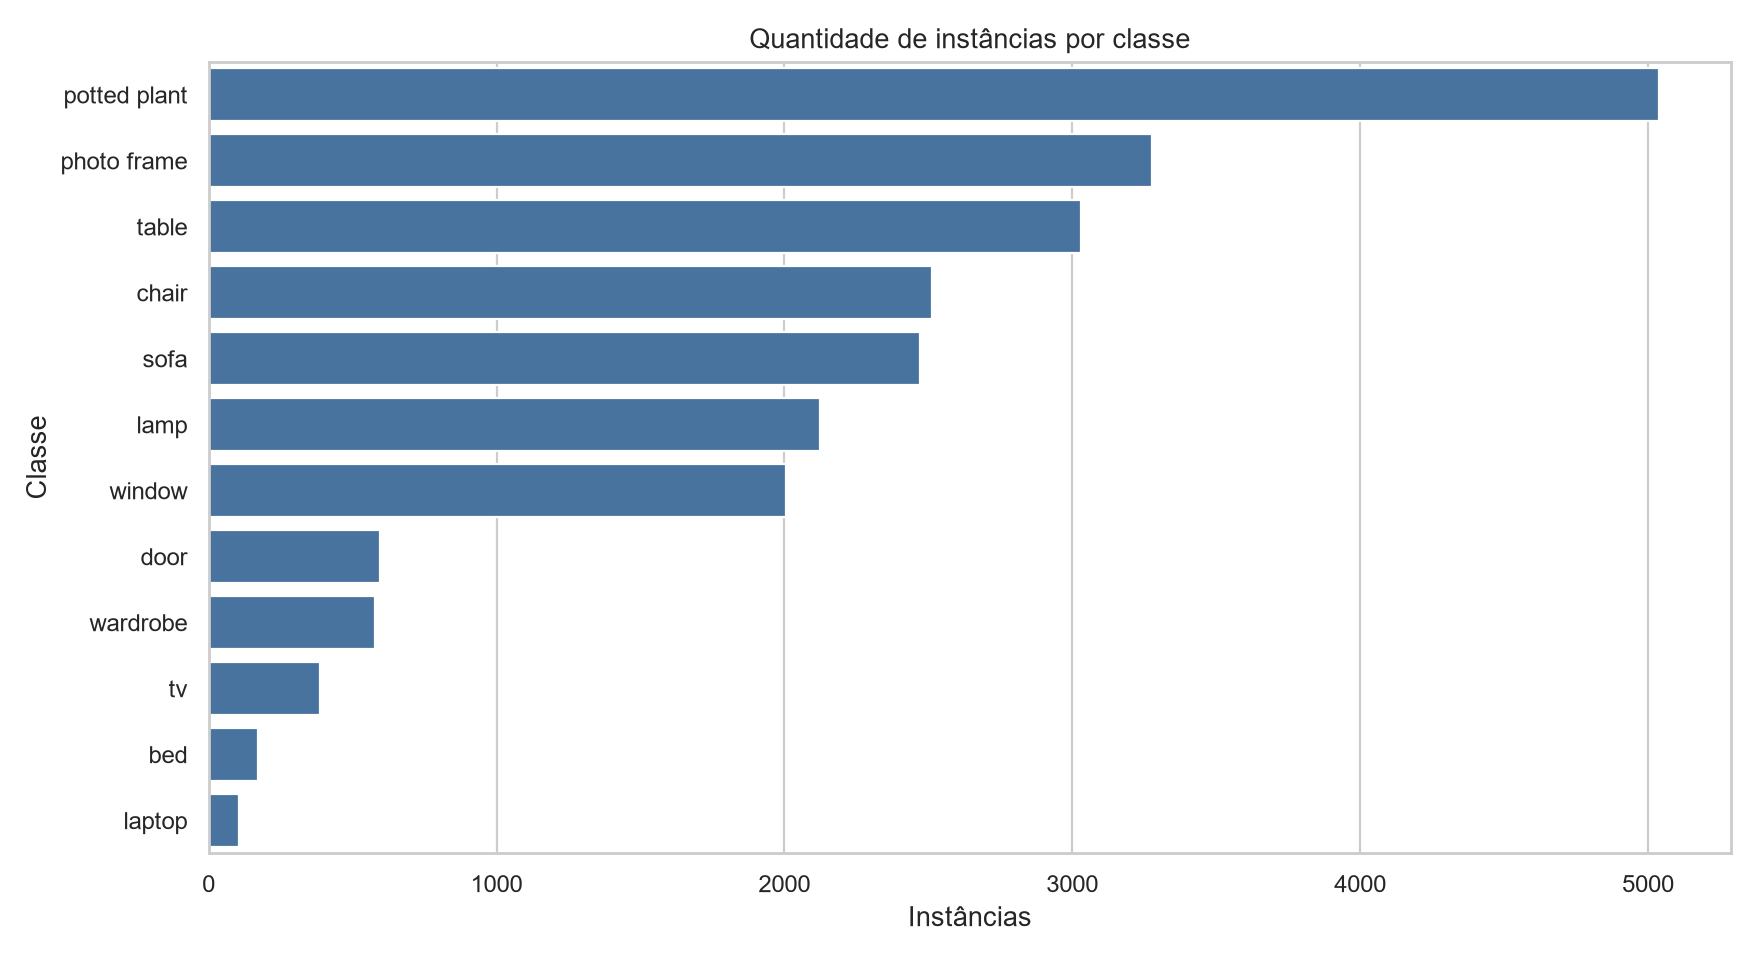

In [7]:
caminho_grafico_classes = PASTA_RELATORIOS / 'figures' / 'distribuicao_instancias.png'
display(ImagemNotebook(filename=str(caminho_grafico_classes)))

## 7. Problemas encontrados

Labels ausentes, anotações inválidas e imagens corrompidas são críticos para a preparação.
Um arquivo de label vazio pode representar uma imagem negativa e recebe somente um aviso.
As contagens não comprovam que as classes e caixas estão semanticamente corretas.


In [8]:
df_problemas = resultados['problemas']

if df_problemas.empty:
    print('Nenhum problema estrutural foi encontrado.')
else:
    display(
        df_problemas.groupby('tipo')
        .size()
        .rename('quantidade')
        .sort_values(ascending=False)
        .reset_index()
    )
    display(df_problemas.head(20))

Nenhum problema estrutural foi encontrado.


## 8. Duplicidades

Duplicidades entre treino e validação podem aumentar artificialmente as métricas. O SHA-256 identifica arquivos idênticos; o dHash igual ajuda a encontrar imagens visualmente semelhantes mesmo quando o arquivo foi recodificado.

In [9]:
df_duplicidades = resultados['duplicidades']

if df_duplicidades.empty:
    print('Nenhuma duplicidade foi encontrada pelos critérios iniciais.')
else:
    print(f'Grupos de duplicidades: {len(df_duplicidades)}')
    display(df_duplicidades)

Grupos de duplicidades: 20


,tipo_hash,hash,quantidade,splits,entre_splits,arquivos
0,sha256,91762dd496112cd20e6ebe02735b26c7f36f1222e5c5e3...,2,train,False,C:\Users\diego\OneDrive\Documentos_One_Drive\T...
1,sha256,b2f509d5f562790e5b552c827975f9ca94a08c0a7786fa...,2,train,False,C:\Users\diego\OneDrive\Documentos_One_Drive\T...
2,sha256,b8fdfea290321d67e244d421808f65aafca81c11e1d002...,2,val,False,C:\Users\diego\OneDrive\Documentos_One_Drive\T...
3,dhash_igual,9ab2b2b2b0b0d8d8,2,train,False,C:\Users\diego\OneDrive\Documentos_One_Drive\T...
4,dhash_igual,e0a0b8d8e96565d8,2,"train, val",True,C:\Users\diego\OneDrive\Documentos_One_Drive\T...
5,dhash_igual,c3d3f176f1f9feff,2,train,False,C:\Users\diego\OneDrive\Documentos_One_Drive\T...
6,dhash_igual,1669711396e4f0f1,2,train,False,C:\Users\diego\OneDrive\Documentos_One_Drive\T...
7,dhash_igual,7f3fb0fd7d7d7d7d,2,train,False,C:\Users\diego\OneDrive\Documentos_One_Drive\T...
8,dhash_igual,91db672733c30721,2,train,False,C:\Users\diego\OneDrive\Documentos_One_Drive\T...
9,dhash_igual,90f0999a148c1c8c,2,train,False,C:\Users\diego\OneDrive\Documentos_One_Drive\T...


## 9. Conferência visual opcional

A grade é gerada pelo código. Olhar algumas amostras ao adicionar uma base nova é útil,
mas não exige registrar respostas, marcar linhas de planilhas nem rotular imagens.


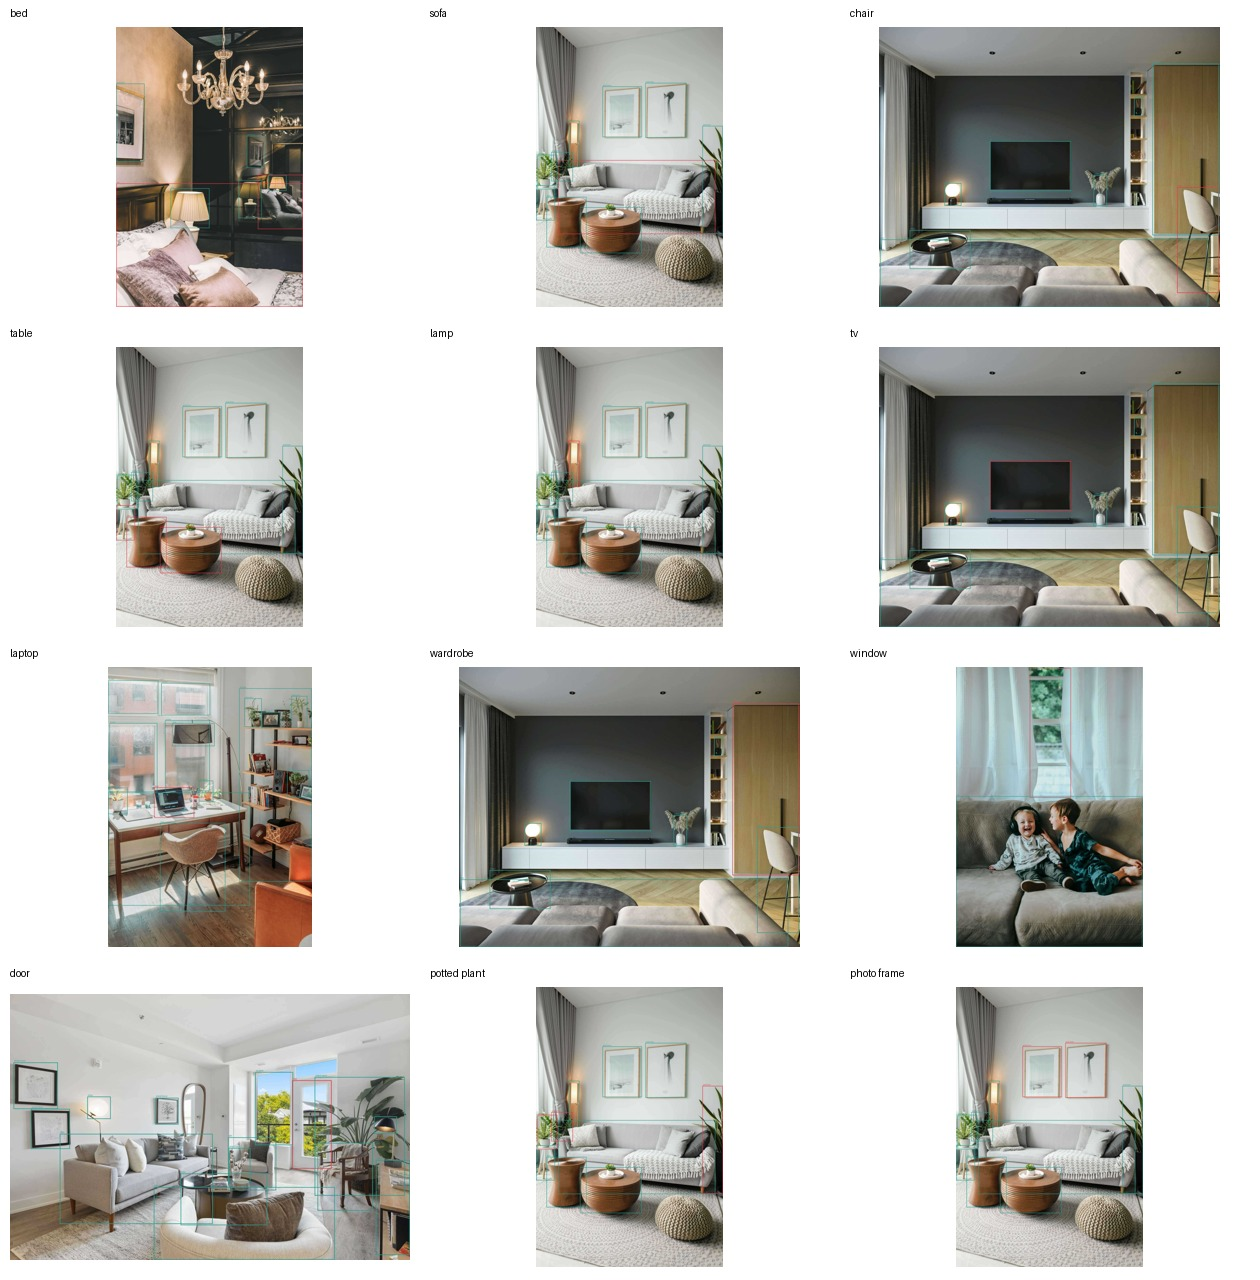

In [10]:
caminho_amostras = PASTA_RELATORIOS / 'figures' / 'amostras_anotadas.jpg'
if caminho_amostras.exists():
    display(ImagemNotebook(filename=str(caminho_amostras)))
else:
    print('A grade não foi gerada porque nenhuma caixa válida foi encontrada.')

## 10. Resultado e decisões já registradas

As 12 classes permanecem no detector. A política V2 está centralizada em
`src/politica_alertas.py`. A saída da aplicação é texto, quando houver alerta.

Nenhum checklist precisa ser preenchido. O próximo código confere os erros críticos
automaticamente. Em caso de falha, o relatório foi salvo para identificar o problema
de origem; o código não inventa anotações para permitir o treinamento.


In [11]:
validar_resultados_auditoria(resultados)
print('Auditoria aprovada estruturalmente. Relatórios:', PASTA_RELATORIOS)


Auditoria aprovada estruturalmente. Relatórios: C:\Users\diego\OneDrive\Documentos_One_Drive\TCC\tcc_visao_computacional\reports\auditoria_automatica\20261012_235355_794032
